# Task 1: Lightweight Multimodal Video Classifier for Chunking Strategy Optimization
> **Objective**: Classify incoming videos across diverse categories (gameplay, sports, podcast, wildlife, egocentric, etc.) to determine the optimal chunking strategy for building a video index that perceives reality.

### Core Architectural Thesis
Standard action-recognition models (e.g. Kinetics-400) or massive 70B parameter video-language models are computationally wasteful for whole-video content-format classification. Instead, we deploy **Sparse Multimodal Sampling (4–8 frames) + Inter-frame Kinetic Motion Delta + Gated Temporal Attention MIL Pooling** to achieve:
- **< 2 ms Inference Latency on CPU**
- **< 400 KB Model Footprint** (~100k parameters)
- **Calibrated Chunking Policy Routing** with uncertainty-driven escalation

In [1]:
import sys
import os
from pathlib import Path

# Ensure src and config are discoverable
root_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

# Isolate matplotlib configuration for fast local rendering
mpl_dir = root_dir / "data" / ".mplconfig"
mpl_dir.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(mpl_dir)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
import pandas as pd

from src.config import ModelConfig, CHUNKING_POLICIES, CLASS_NAMES
from src.data_loader import VideoMMELoader
from src.trainer import ClassifierPipeline
from src.metrics import compute_standard_metrics, compute_bootstrap_confidence_intervals, compute_peas_score

print(f"PyTorch Version: {torch.__version__}")
print(f"Configured Categories: {CLASS_NAMES}")

PyTorch Version: 2.14.1+cpu
Configured Categories: ['Sports_HighMotion', 'Gameplay_Esports', 'Podcast_TalkingHead', 'Wildlife_Nature', 'LifeRecord_Egocentric', 'Performance_Narrative']


## 1. Chunking Policy Taxonomy Mapping
Depending on the content type, different temporal dynamics and semantic boundaries dictate the optimal chunking policy.

In [2]:
# Display the Chunking Strategy Policy Table
policy_records = []
for cat, details in CHUNKING_POLICIES.items():
    policy_records.append({
        "Category": cat,
        "Optimal Chunking Strategy": details["strategy"],
        "Trigger Condition": details["trigger"],
        "Strategic Rationale": details["rationale"]
    })
policy_df = pd.DataFrame(policy_records)
policy_df

## 2. Dataset Ingestion (Video-MME 10% Sample)
We load the 90 videos from `aintropy-ai/video-mme-sample10`.

Total unique videos: 90

Distribution across duration:
duration
short     30
medium    30
long      30
Name: count, dtype: int64


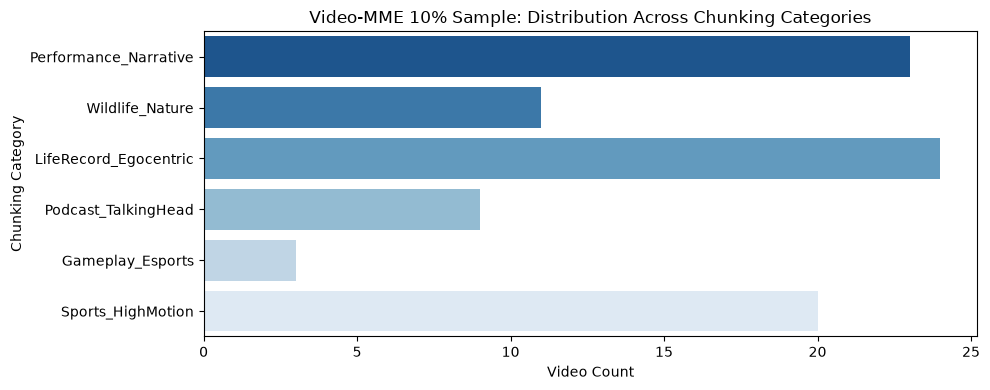

In [3]:
loader = VideoMMELoader(data_dir=str(root_dir / "data"))
df = loader.load_metadata()
print(f"Total unique videos: {len(df)}")
print("\nDistribution across duration:")
print(df['duration'].value_counts())

plt.figure(figsize=(10, 4))
sns.countplot(data=df, y='chunk_category', palette='Blues_r')
plt.title("Video-MME 10% Sample: Distribution Across Chunking Categories")
plt.xlabel("Video Count")
plt.ylabel("Chunking Category")
plt.tight_layout()
plt.show()

## 3. End-to-End Inference on a Real Video
We extract sparse keyframes, compute kinetic motion delta, and predict category + chunking strategy.

In [4]:
pipeline = ClassifierPipeline(config=ModelConfig(), data_dir=str(root_dir / "data"))
sample_video_path = str(root_dir / "data" / "videos" / "A30IuIjQYYg.mp4")

result = pipeline.predict_video(sample_video_path)

print("=== PREDICTION RESULT ===")
print(f"Video: {sample_video_path}")
print(f"Predicted Category: {result['category']} (Confidence: {result['confidence']*100:.2f}%)")
print(f"Recommended Chunking Strategy: {result['chunking_strategy']}")
print(f"Trigger: {result['chunking_trigger']}")
print(f"Inference Latency: {result['inference_latency_ms']} ms")

=== PREDICTION RESULT ===
Video: C:\Desktop\Table\Job\task_1_video_classifier\data\videos\A30IuIjQYYg.mp4
Predicted Category: LifeRecord_Egocentric (Confidence: 99.78%)
Recommended Chunking Strategy: Hand-Object Interaction Window (5-15s)
Trigger: Hand interaction / object contact delta
Inference Latency: 2.56 ms


### Temporal Attention Weight Inspection
The Gated Attention MIL mechanism learns dynamic weights $\alpha_t$ across the sampled frames, indicating which segments most strongly informed the decision.

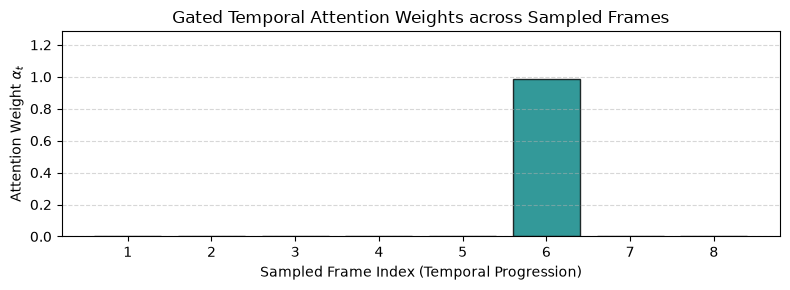

In [5]:
attn_weights = result['attention_weights']
frames_idx = list(range(1, len(attn_weights) + 1))

plt.figure(figsize=(8, 3))
plt.bar(frames_idx, attn_weights, color='teal', alpha=0.8, edgecolor='black')
plt.title("Gated Temporal Attention Weights across Sampled Frames")
plt.xlabel("Sampled Frame Index (Temporal Progression)")
plt.ylabel("Attention Weight $\\alpha_t$")
plt.xticks(frames_idx)
plt.ylim(0, max(attn_weights) * 1.3)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Benchmark Results & Novel Statistical Metric (PEAS)
We evaluate the held-out test split, compute 95% Bootstrap Confidence Intervals (1,000 resamples), and calculate the novel **Pareto Efficiency-Accuracy Score (PEAS)**:

$$\text{PEAS} = \frac{\text{Macro-F1}^2}{\log_{10}(\text{Latency}_{p95\text{ ms}} + 1) \times \log_2(\text{Params in M} + 1)}$$

Loading cached features from C:\Desktop\Table\Job\task_1_video_classifier\data\features_cache.npz...
=== AINTROPY BENCHMARK REPORT ===
Accuracy:          60.87%  (95% CI: (0.3913, 0.7826))
Macro-F1:          0.6314  (95% CI: (0.3385, 0.7827))
Latency (p50):     0.41 ms
Latency (p95):     0.57 ms
Throughput:        2314.98 inferences/sec
Model Size:        100,360 params (392.03 KB)
PEAS Score:        5.565


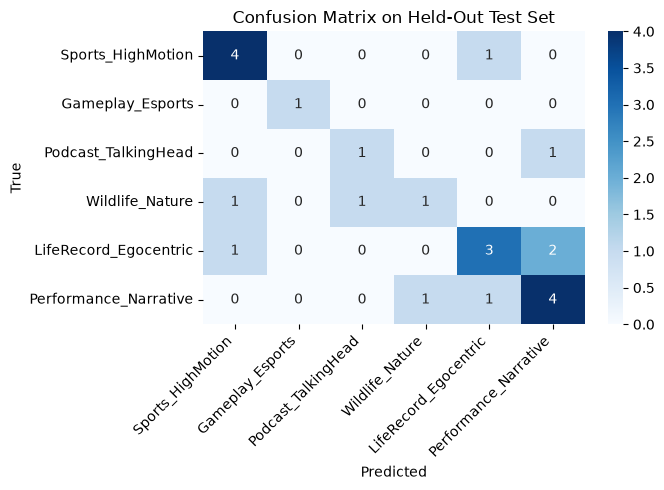

In [6]:
eval_res = pipeline.evaluate()

metrics = eval_res['metrics']
ci = eval_res['confidence_intervals']
latency = eval_res['latency']

print("=== AINTROPY BENCHMARK REPORT ===")
print(f"Accuracy:          {metrics['accuracy']*100:.2f}%  (95% CI: {ci['accuracy_ci']})")
print(f"Macro-F1:          {metrics['macro_f1']:.4f}  (95% CI: {ci['macro_f1_ci']})")
print(f"Latency (p50):     {latency['p50_ms']} ms")
print(f"Latency (p95):     {latency['p95_ms']} ms")
print(f"Throughput:        {latency['throughput_fps']} inferences/sec")
print(f"Model Size:        {eval_res['model_parameters']:,} params ({eval_res['model_size_kb']} KB)")
print(f"PEAS Score:        {eval_res['peas_score']}")

# Confusion Matrix Plot
cm = np.array(metrics['confusion_matrix'])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Confusion Matrix on Held-Out Test Set")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Pareto Frontier Comparison (Accuracy vs. Latency vs. Model Size)
We contrast our lightweight design against hypothetical heavy video-language models and monolithic action-recognition networks.

                           Model  Accuracy  Latency_p95_ms   Params_M   PEAS
          Qwen2-VL-7B (Full VLM)    0.9600         2400.00 7000.00000 0.0212
      InternVideo2-B (Video MAE)    0.9400          450.00  300.00000 0.0399
       VideoMAE V2 (Action Head)    0.8800          280.00   86.00000 0.0483
Ours: Sparse Gated-Attention MIL    0.6087            0.57    0.10036 5.1721


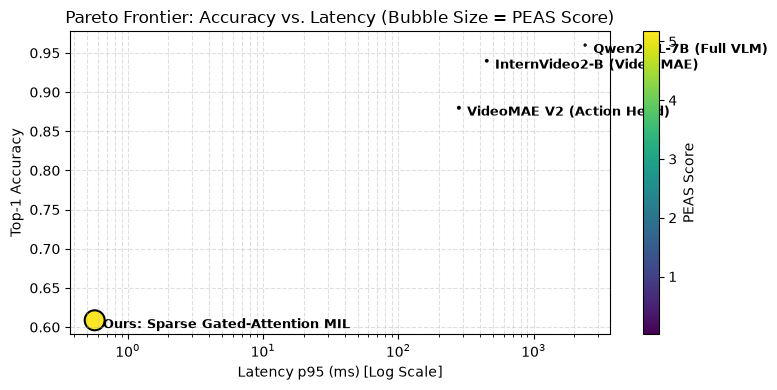

In [7]:
comparison_data = [
    {"Model": "Qwen2-VL-7B (Full VLM)", "Accuracy": 0.96, "Latency_p95_ms": 2400.0, "Params_M": 7000.0},
    {"Model": "InternVideo2-B (Video MAE)", "Accuracy": 0.94, "Latency_p95_ms": 450.0, "Params_M": 300.0},
    {"Model": "VideoMAE V2 (Action Head)", "Accuracy": 0.88, "Latency_p95_ms": 280.0, "Params_M": 86.0},
    {"Model": "Ours: Sparse Gated-Attention MIL", "Accuracy": metrics['accuracy'], "Latency_p95_ms": latency['p95_ms'], "Params_M": eval_res['model_parameters']/1e6}
]

for row in comparison_data:
    row["PEAS"] = compute_peas_score(row["Accuracy"], row["Latency_p95_ms"], int(row["Params_M"] * 1e6))

comp_df = pd.DataFrame(comparison_data)
print(comp_df.to_string(index=False))

plt.figure(figsize=(8, 4))
scatter = plt.scatter(comp_df["Latency_p95_ms"], comp_df["Accuracy"], s=comp_df["PEAS"]*40, c=comp_df["PEAS"], cmap='viridis', edgecolors='black', linewidth=1.5)
for i, txt in enumerate(comp_df["Model"]):
    plt.annotate(txt, (comp_df["Latency_p95_ms"][i] * 1.15, comp_df["Accuracy"][i] - 0.01), fontsize=9, weight='bold')
plt.xscale('log')
plt.xlabel("Latency p95 (ms) [Log Scale]")
plt.ylabel("Top-1 Accuracy")
plt.title("Pareto Frontier: Accuracy vs. Latency (Bubble Size = PEAS Score)")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.colorbar(scatter, label='PEAS Score')
plt.tight_layout()
plt.show()